# 09 · Phase 2 additions: novelty flags, Isolation Forest, a stronger baseline, the scorer and the gate

**FinGuard AI, Phase 2 (completed).** Project Report v3.0 listed five Phase 2 items that the
first Phase 2 run left out. This notebook reads `python -m finguard.phase2b` outputs.

1. Explainable novelty flags, and whether they belong in the score.
2. Isolation Forest, alone and as an extra LightGBM input.
3. Why the baseline scored 0.419 against the design review's 0.445, and the strengthened baseline.
4. The calibrated 0-100 scorer the analyst tools will call (online = batch, checked).
5. The model gate and the registry entry.

The test month (days 152-181) is only scored; every choice is made on the validation month.

In [1]:
import sys, pathlib, json
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from finguard import config, phase2
from finguard.evaluation import figures as F
from finguard.evaluation import metrics as M
from finguard.models import dataset

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 120)
T, A = config.TABLE_DIR, phase2.ART
load = lambda p: json.loads((A / p / "info.json").read_text())
fs = dataset.load("main", "numeric")
y_te = fs.y[fs.masks["test"]].astype(int)
main = phase2.load_preds("lgbm_numeric")
print("test transactions:", len(y_te), "| frauds:", int(y_te.sum()))

test transactions: 85430 | frauds: 2994


## 1. Novelty flags
Three rules on each proxy entity's earlier transactions (thresholds fixed in advance):
a new device brand, a burst of at least 4 transactions within 24 h of first use, and an
amount more than 3x the largest earlier amount. Rates below use transactions that have a
proxy-entity key (rows without one are 13.7% fraud and are reported in notebook 08).

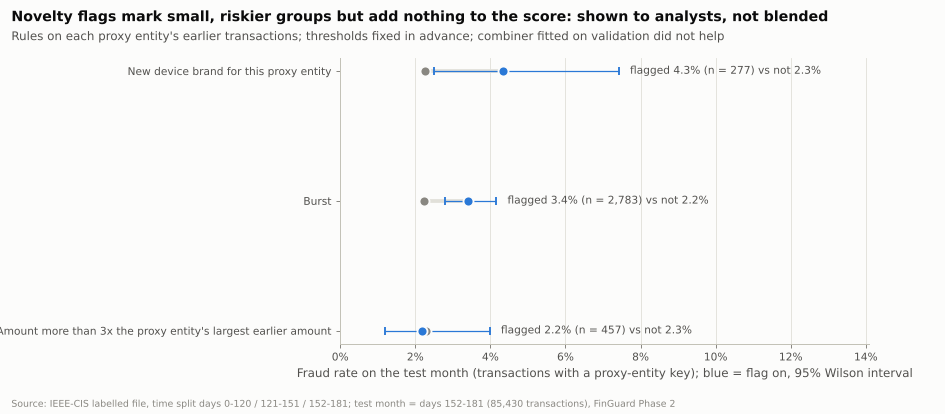

,flag,group,n,share_of_keyed_rows,frauds,fraud_rate,lo,hi
0,flag_new_device,flag on,277,0.003631,12,0.043321,0.024952,0.074184
1,flag_new_device,flag off,76018,0.996369,1726,0.022705,0.021670,0.023788
2,flag_burst_first_day,flag on,2783,0.036477,95,0.034136,0.028006,0.041550
3,flag_burst_first_day,flag off,73512,0.963523,1643,0.022350,0.021306,0.023444
4,flag_amount_above_max,flag on,457,0.005990,10,0.021882,0.011928,0.039807
5,flag_amount_above_max,flag off,75838,0.994010,1728,0.022785,0.021747,0.023872


In [2]:
nov = load("novelty")
rates = pd.DataFrame(nov["rates"])
test_rates = rates[rates.part == "test"].reset_index(drop=True)
fig = F.fig25_novelty_flags(test_rates)
test_rates[["flag", "group", "n", "share_of_keyed_rows", "frauds", "fraud_rate", "lo", "hi"]]

In [3]:
print("fraud rate inside each band, test month, with and without any flag:")
display(pd.DataFrame(nov["within_test_bands"]))
c = nov["combiner"]
print("combiner inputs:", c["inputs"])
print("validation (two time-ordered halves) PR-AUC gain:", np.round(c["valid_time_cv_pr_auc_gain"], 4))
print("test PR-AUC gain (for the record):", round(c["paired_test_combined_minus_main"]["pr_auc"]["difference"], 4),
      np.round(c["paired_test_combined_minus_main"]["pr_auc"]["ci95"], 4))
print("decision:", c["decision"], "| rule:", c["rule"])

fraud rate inside each band, test month, with and without any flag:


,band,group,n,fraud_rate
0,High,any flag,13,0.923077
1,High,no flag,781,0.900128
2,Medium,any flag,245,0.146939
3,Medium,no flag,3758,0.316924
4,Low,any flag,3103,0.019981
5,Low,no flag,77530,0.012769


combiner inputs: ['raw score', 'flag_new_device', 'flag_burst_first_day', 'flag_amount_above_max', 'no entity key']
validation (two time-ordered halves) PR-AUC gain: [-0.0003 -0.0033]
test PR-AUC gain (for the record): 0.001 [0.0003 0.0016]
decision: keep flags as displayed indicators only | rule: blend only if both time-ordered halves of the validation month gain PR-AUC


## 2. Isolation Forest
Alone: fitted on training-period legitimate transactions (as the report specifies). As a
feature: refitted on all training-period transactions without labels, so that training frauds
do not look unusual merely because they were left out of the fit.

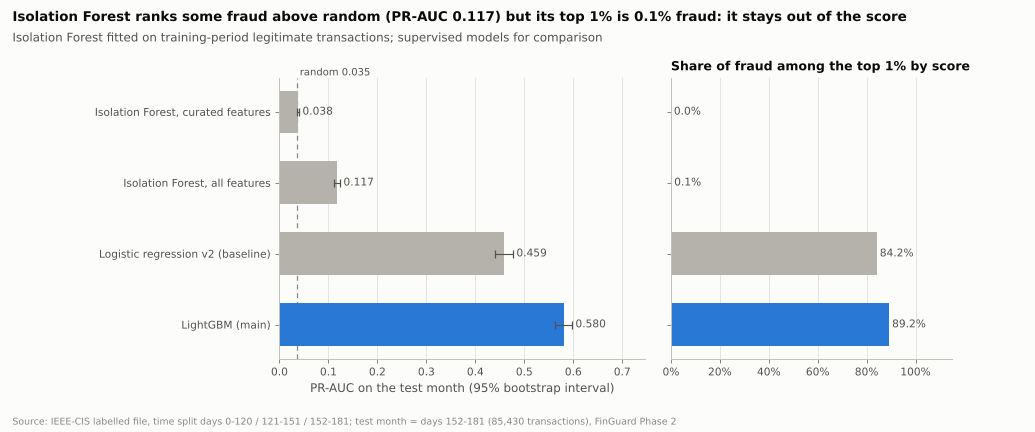

,label,pr_auc,lo,hi,precision_at_1,valid_pr_auc,overlap_top1_with_lightgbm
0,"Isolation Forest, curated features",0.037914,0.036436,0.039817,0.000000,0.041187,0.000000
1,"Isolation Forest, all features",0.117353,0.111274,0.123542,0.001171,0.174627,0.001171
2,Logistic regression v2 (baseline),0.458550,0.439626,0.476711,0.841920,NaN,NaN
3,LightGBM (main),0.580483,0.561981,0.597294,0.892272,NaN,NaN


In [4]:
iso = load("iforest")
iso_rows = []
for v, label in (("curated", "Isolation Forest, curated features"), ("all", "Isolation Forest, all features")):
    r = iso["variants"][v]
    iso_rows.append({"label": label, "pr_auc": r["test"]["pr_auc"], "lo": r["test_ci95"][0], "hi": r["test_ci95"][1],
                     "precision_at_1": r["test"]["precision@1%"], "valid_pr_auc": r["valid"]["pr_auc"],
                     "overlap_top1_with_lightgbm": r["test"]["overlap_top1pct_with_lightgbm"], "highlight": False})
lr2 = load("lr_v2")
res6 = json.loads((T / "phase2_results.json").read_text())
iso_rows.append({"label": "Logistic regression v2 (baseline)", "pr_auc": lr2["test"]["pr_auc"], "lo": lr2["test_ci95"]["pr_auc"][0],
                 "hi": lr2["test_ci95"]["pr_auc"][1], "precision_at_1": lr2["test"]["precision@1%"], "highlight": False})
iso_rows.append({"label": "LightGBM (main)", "pr_auc": res6["test_metrics"]["LightGBM"]["pr_auc"],
                 "lo": res6["bootstrap_ci95"]["LightGBM"]["pr_auc"][0], "hi": res6["bootstrap_ci95"]["LightGBM"]["pr_auc"][1],
                 "precision_at_1": res6["test_metrics"]["LightGBM"]["precision@1%"], "highlight": True})
unsup = pd.DataFrame(iso_rows)
fig = F.fig26_unsupervised(unsup, float(y_te.mean()))
unsup.drop(columns="highlight")

In [5]:
feat = load("iforest_feature")
d = feat["paired_test_with_minus_without"]["pr_auc"]
pd.DataFrame({"LightGBM": {"valid PR-AUC": load("lgbm_numeric")["valid"]["pr_auc"], "test PR-AUC": res6["test_metrics"]["LightGBM"]["pr_auc"]},
              "LightGBM + Isolation Forest score": {"valid PR-AUC": feat["valid"]["pr_auc"], "test PR-AUC": feat["test"]["pr_auc"]}}).T.assign(
    note=["", f"test difference {d['difference']:+.4f} (95% {d['ci95'][0]:+.4f} to {d['ci95'][1]:+.4f}); "
              f"importance rank {feat['iforest_gain_rank']} of {feat['n_features']}"])

,valid PR-AUC,test PR-AUC,note
LightGBM,0.659172,0.580483,
LightGBM + Isolation Forest score,0.657070,0.580269,test difference -0.0002 (95% -0.0040 to +0.0033); importance rank 1 of 474


## 3. The baseline gap and the strengthened baseline
The design review's baseline (0.445) used different preprocessing. Re-running it on the full
training window, then applying the Phase 1 rules one at a time, isolates the cause.

In [6]:
lv = pd.DataFrame(load("lr_variants")["variants"])
lv["test_ci95"] = lv.test_ci95.map(lambda c: f"{c[0]:.3f}-{c[1]:.3f}")
lv["meaning"] = lv.variant.map(load("lr_variants")["meaning"])
lv.loc[len(lv)] = {"variant": "phase2_lr (notebook 05)", "inputs": 621, "C": 0.01, "valid_pr_auc": load("lr")["valid"]["pr_auc"],
                   "test_pr_auc": load("lr")["test"]["pr_auc"], "test_ci95": "0.400-0.438", "recall@5%": load("lr")["test"]["recall@5%"],
                   "meaning": "Phase 2 preprocessing: log only for heavy tails, duplicates dropped, frequencies for codes"}
lv[["variant", "inputs", "C", "valid_pr_auc", "test_pr_auc", "test_ci95", "meaning"]]

,variant,inputs,C,valid_pr_auc,test_pr_auc,test_ci95,meaning
0,review_style,502,0.01,0.470250,0.456406,0.438-0.476,design-review preprocessing: raw D columns and card/address codes as numbers
1,d_reexpressed,502,0.01,0.470851,0.458162,0.440-0.477,"same, trending D columns as day - D"
2,no_codes,494,0.01,0.468811,0.457426,0.439-0.477,"same, card/address codes removed"
3,both,494,0.01,0.469377,0.458550,0.440-0.478,trending D re-expressed and codes removed
4,phase2_lr (notebook 05),621,0.01,0.448154,0.419381,0.400-0.438,"Phase 2 preprocessing: log only for heavy tails, duplicates dropped, frequencies for codes"


In [7]:
p = lr2["paired_lightgbm_minus_lr_v2"]
print(f"strengthened baseline (v2): test PR-AUC {lr2['test']['pr_auc']:.4f}  "
      f"[{lr2['test_ci95']['pr_auc'][0]:.3f}-{lr2['test_ci95']['pr_auc'][1]:.3f}], C = {lr2['C']}")
print(f"LightGBM - baseline v2: {p['pr_auc']['difference']:+.4f} (95% {p['pr_auc']['ci95'][0]:+.4f} to {p['pr_auc']['ci95'][1]:+.4f}); "
      f"recall@5% {p['recall@5%']['difference']:+.4f}")
pd.DataFrame({"Logistic regression v2": lr2["test"]}).T[["pr_auc", "roc_auc", "precision@1%", "recall@1%", "precision@5%", "recall@5%"]]

strengthened baseline (v2): test PR-AUC 0.4586  [0.440-0.477], C = 0.01
LightGBM - baseline v2: +0.1219 (95% +0.1090 to +0.1355); recall@5% +0.1212


,pr_auc,roc_auc,precision@1%,recall@1%,precision@5%,recall@5%
Logistic regression v2,0.45855,0.868278,0.84192,0.240147,0.352294,0.502672


## 4. The scorer
`finguard.serving.Scorer` returns what the `fraud_score` and `explain_transaction` tools
will: a 0-100 score (100 x calibrated probability), the band, the model version, the
novelty flags and the top-5 reason families. Anonymized families name their signal group.
The online path (one transaction + its proxy entity's earlier transactions from the
`EntityStore`) must equal the batch features.

In [8]:
from finguard.data.ingest import load_table
from finguard.serving.entity_store import EntityStore
from finguard.serving.scorer import Scorer
sc = Scorer()
table = load_table("train").reset_index(drop=True)
store = EntityStore(table)
rs = np.random.RandomState(0)
check_rows = rs.choice(np.flatnonzero(fs.masks["test"]), 200, replace=False)
cached = sc.score_cached(table.loc[check_rows, "TransactionID"].tolist(), explain=False)
diff = max(abs(sc.score_transaction(table.iloc[[r]], store.history(table.iloc[[r]]), explain=False)["score"] - c["score"])
           for r, c in zip(check_rows, cached))
print(f"model version: {sc.model_version}")
print(f"max |online score - batch score| over 200 random test-month transactions: {diff}")

model version: lgbm_numeric-v1
max |online score - batch score| over 200 random test-month transactions: 0.0


In [9]:
test_rows = np.flatnonzero(fs.masks["test"])
is_high = main["test_raw"] >= sc.bands.high
has_key = table["addr1"].notna().to_numpy()[test_rows] & table["D1"].notna().to_numpy()[test_rows]
example = table.iloc[[test_rows[np.flatnonzero(is_high & has_key)[0]]]]
out = sc.score_transaction(example, store.history(example))
print(json.dumps({k: v for k, v in out.items() if k != "reasons"}, indent=1))
pd.DataFrame(out["reasons"])[["label", "checkable", "contribution_log_odds", "signal_group", "text"]]

{
 "transaction_id": 3492819,
 "score": 99.0,
 "probability_displayed": ">99%",
 "band": "High",
 "model_version": "lgbm_numeric-v1",
 "novelty_flags": [
  {
   "flag": "flag_new_device",
   "on": false,
   "rule": "New device brand for this proxy entity (another brand was used before)"
  },
  {
   "flag": "flag_burst_first_day",
   "on": false,
   "rule": "Burst: at least 4 transactions within 24 h of the proxy entity's first transaction"
  },
  {
   "flag": "flag_amount_above_max",
   "on": false,
   "rule": "Amount more than 3x the proxy entity's largest earlier amount"
  }
 ],
 "notes": [
  "Flagged for review, not a finding of fraud.",
  "Reasons explain the model's score, not the cause of fraud.",
  "Proxy entity = card1 + addr1 + first-seen day: a heuristic grouping, not a customer."
 ]
}


,label,checkable,contribution_log_odds,signal_group,text
0,Anonymized counting features (C1-C14),False,9.005,C13,Anonymized counting features (C1-C14): meaning not disclosed by the data provider; largest contribution from anonymi...
1,Vesta engineered features (V1-V339),False,5.585,V167-V216,Vesta engineered features (V1-V339): meaning not disclosed by the data provider; largest contribution from anonymize...
2,Device and browser,True,2.358,NaN,"Device and browser: mobile, brand other, OS android, browser chrome."
3,Anonymized time-delta features (D1-D15),False,1.957,D15n,Anonymized time-delta features (D1-D15): meaning not disclosed by the data provider; largest contribution from anony...
4,Amount,True,1.316,NaN,Amount: 200.00 (0 non-zero decimal place(s)).


In [10]:
print(json.dumps(store.summary(example), indent=1))

{
 "entity": "proxy entity (card1 + addr1 + first-seen day); a heuristic grouping, not a customer",
 "entity_key": "13351_299_148",
 "available": true,
 "earlier_transactions": 1,
 "earlier_in_24h": 0,
 "earlier_in_7d": 1,
 "seconds_since_previous": 440231.0,
 "days_since_first": 5.095266203703703,
 "amount": 200.0,
 "earlier_amount_mean": 150.0,
 "earlier_amount_max": 150.0,
 "amount_vs_earlier_mean": 1.3333333333333333,
 "device_brands_seen": [
  "other"
 ],
 "purchaser_email_domains_seen": [
  "yahoo.com"
 ]
}


## 5. Model gate and registry

In [11]:
from finguard import gate, registry
report = gate.run()
entry = registry.register("lgbm_numeric", gate_report=report)
print("gate:", "PASSED" if report["passed"] else "FAILED", "| registered as", entry["model_id"], "| code", entry["code"])
print("promotion to champion is a human step:",
      f'python -m finguard.registry promote {entry["model_id"]} --alias champion --approved-by "<name>"')
pd.DataFrame(report["checks"])

gate: PASSED | registered as lgbm_numeric-v1 | code src:b8264059eeec
promotion to champion is a human step: python -m finguard.registry promote lgbm_numeric-v1 --alias champion --approved-by "<name>"


,gate,check,passed,detail
0,Data,Phase 1 data-quality checks,True,"0 FAIL, 6 WARN"
1,Leakage,no forbidden or ID/time-like input,True,473 inputs; offending: none
2,Leakage,statistics fitted on training rows only,True,"fit rows 417,559 = training rows 417,559"
3,Leakage,time split ordered and disjoint,True,"train 0-120, valid 121-151, test 152-181"
4,Model,PR-AUC interval entirely above the strongest baseline,True,LightGBM entity-block 95% lower bound 0.552 vs logistic regression v2 (strengthened) 0.459
5,Model,not worse than the champion,True,no champion registered yet
6,Calibration,calibrated Brier below raw,True,0.0208 vs raw 0.0221
7,Calibration,band fraud rates High > Medium > Low (test),True,"High 90.1%, Medium 30.7%, Low 1.3%"
8,Explainability,TreeSHAP local accuracy,True,max |sum SHAP - score| = 1.9e-09
9,Explainability,no ID/time-like feature in the top 20,True,"top 3: C13, TransactionAmt, D1n; offending: none"


In [12]:
summary = {"novelty": {"decision": c["decision"], "test_rates": test_rates.to_dict("records")},
           "isolation_forest": unsup.drop(columns="highlight").to_dict("records"),
           "iforest_feature": {"test_pr_auc": feat["test"]["pr_auc"], "paired_difference": d, "gain_rank": feat["iforest_gain_rank"]},
           "baseline_variants": lv.drop(columns="test_ci95").to_dict("records"),
           "baseline_v2": {"test": lr2["test"], "ci95": lr2["test_ci95"]["pr_auc"], "paired_lightgbm_minus_v2": p},
           "scorer": {"model_version": sc.model_version, "online_vs_batch_max_abs_diff": diff},
           "gate": {"passed": report["passed"], "model_id": entry["model_id"]}}
(T / "phase2b_summary.json").write_text(json.dumps(summary, indent=1, default=float))
print("saved reports/tables/phase2b_summary.json")

saved reports/tables/phase2b_summary.json
